# Selected-well A260 and DNA concentration — FilterMax F5

Enter wells such as **`"A8, A9"`** and run the cells in order. Include a blank:
the **lowest finite raw A260** is treated as the blank, and all other finite readings
are treated as samples. At least two finite readings are required for analysis.
If minima are tied, the first well in your entered order is the blank.

The calibration is **`blank-corrected A260 = 0.00338 × concentration + 0.0022`**.
Reported concentrations include a **10× dilution factor**. The calculation applies
this calibration directly, without an additional volume or pathlength correction.

This notebook uses the adjacent `read_dna_a260_selected_wells.py` and
`filtermax_slides.xml`; no experiment folder or plate map is required. Use a Python
kernel with PyLabRobot, pandas, Matplotlib, and IPython installed.

The F5 scans complete rows from the first selected row through the last selected row;
only the selected wells are retained in the returned data and CSV.

## 1. Enter wells

Use comma-separated names from A1 through H12. Spaces and lowercase are accepted;
empty entries and duplicate or out-of-range names are rejected. For your three-well
example, enter `"A9, A10, A12"`. Rerun this cell after editing.

In [12]:
WELLS_TO_READ = "A9, A10, A12"

## 2. Load the helper and settings

This cell does not connect hardware. The defaults retain the reader's existing port,
serial number, and Costar 96-well portrait profile. Use a matching UV-transparent plate;
the profile is not independently calibrated for a different plate by this notebook.
Edit the settings if your setup differs. `geometry_path` can point to a PlateGeometry
JSON file; `None` selects the default profile.

In [13]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

HELPER_DIR = Path("/home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts")
PLR_CHECKOUT = Path("/home/hamilton-robot/Documents/Hamilton-Starlet/pylabrobot")
for folder in (PLR_CHECKOUT, HELPER_DIR):
  if str(folder) not in sys.path:
    sys.path.insert(0, str(folder))

import read_dna_a260_selected_wells as a260  # noqa: E402 — configure local paths first.

importlib.reload(a260)
reader_settings = {
  "port": a260.DEFAULT_PORT,
  "expected_serial": a260.EXPECTED_SERIAL,
  "catalog_path": HELPER_DIR / "filtermax_slides.xml",
  "geometry_path": None,
  "results_root": HELPER_DIR / "runs",
  "notebook_path": HELPER_DIR / "read_dna_a260_selected_wells.ipynb",
}
last_run_dir = None
print("Reader helper:", a260.__file__)
print("PyLabRobot:", a260.pylabrobot.__file__)

Reader helper: /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/read_dna_a260_selected_wells.py
PyLabRobot: /home/hamilton-robot/Documents/Hamilton-Starlet/pylabrobot/pylabrobot/__init__.py


## 3. Preview without hardware

Validate the wells, catalog, and geometry. This preview does not open a serial port,
move the tray, or create a results directory. The read cell creates a fresh plan from
the current settings when it runs.

In [14]:
preview_plan = a260.prepare_read(WELLS_TO_READ, **reader_settings)
print("Selected wells:", ", ".join(preview_plan.wells))
print("Hardware scans rows:", ", ".join(preview_plan.metadata["hardware_rows"]))
print("Wavelength:", a260.WAVELENGTH, "nm")
print("Reader serial:", preview_plan.expected_serial)
print("Plate profile:", preview_plan.geometry.name)
display(pd.DataFrame({"Well": preview_plan.wells}))
print("OFFLINE ONLY: no reader connected, tray moved, or data generated.")

Selected wells: A9, A10, A12
Hardware scans rows: A
Wavelength: 260 nm
Reader serial: 1191
Plate profile: 96 Well Costar clear [Portrait]


,Well
0,A9
1,A10
2,A12


OFFLINE ONLY: no reader connected, tray moved, or data generated.


## 4. Read A260

Close SoftMax Pro and other connections to the reader. Leave `RUN_READER = False`
for an offline preview. Set it to **`True`** and execute this cell to connect the
reader and open the tray. Load the plate in the displayed orientation, remove its
lid/seal, and clear the tray path. Type **`LOADED`** to start measurement.

`LOADED` is the only input prompt. Any other response cancels measurement. Each run
uses a fresh directory under `helper-scripts/runs/`. The raw CSV, backend JSON, and
reader metadata are saved before concentration analysis; the reader ejects the plate
and the connection is closed after acquisition.

### Portrait plate orientation

Top view while standing at the front of the reader. **A1 goes in the upper-right corner, nearest the instrument.** Row A runs down the right edge to A12, nearest you. This diagram applies to the default **portrait** plate profile.

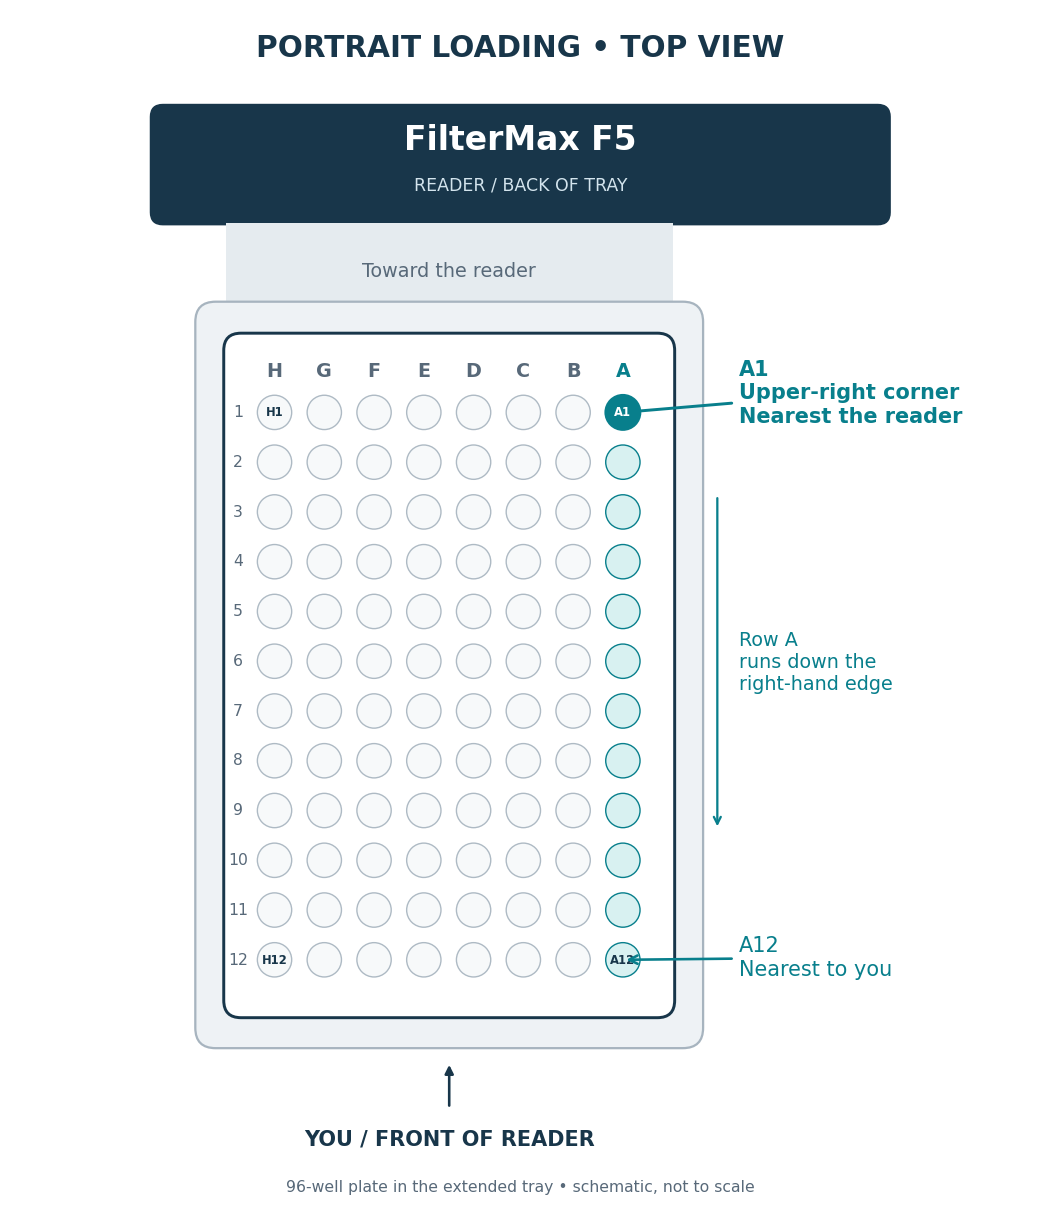

Reference: [SoftMax Pro User Guide, Plate Type Settings](https://moldevkb.blob.core.windows.net/kb01/documents/br/softmaxpro/smp-7.3/softmax-pro-user-guide_5312581a.pdf).

Seat the plate in this orientation before entering **`LOADED`**.

In [15]:
RUN_READER = True

last_run_dir = None
if RUN_READER:
  run_plan = a260.prepare_read(WELLS_TO_READ, **reader_settings)
  last_run_dir = await a260.acquire_selected(run_plan)
else:
  print("Offline mode. Set RUN_READER = True and rerun this cell to read the plate.")

2026-10-08 10:28:59,605 - pylabrobot.molecular_devices.filtermax.filtermax_f5 - INFO - [DNA_A260_selected] connecting to /dev/serial/by-id/usb-Prolific_Technology_Inc._USB-Serial_Controller_BFADb2A8J14-if00-port0 at 38400 baud
2026-10-08 10:28:59,606 - pylabrobot.io.serial - INFO - Using explicitly provided port: /dev/serial/by-id/usb-Prolific_Technology_Inc._USB-Serial_Controller_BFADb2A8J14-if00-port0 (for VID=None, PID=None)


Read 3 wells at 260 nm: A9, A10, A12
Hardware scans rows: A
Results directory: /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/runs/dna-a260-selected-20261008T142859Z-796dba1c
Close SoftMax Pro and any other connection to the F5. Transfer the plate manually.


2026-10-08 10:29:04,727 - pylabrobot.molecular_devices.filtermax.filtermax_f5 - INFO - [DNA_A260_selected] no initial handshake response at 38400 baud
2026-10-08 10:29:04,727 - pylabrobot.molecular_devices.filtermax.filtermax_f5 - INFO - [DNA_A260_selected] connecting to /dev/serial/by-id/usb-Prolific_Technology_Inc._USB-Serial_Controller_BFADb2A8J14-if00-port0 at 9600 baud
2026-10-08 10:29:04,728 - pylabrobot.io.serial - INFO - Using explicitly provided port: /dev/serial/by-id/usb-Prolific_Technology_Inc._USB-Serial_Controller_BFADb2A8J14-if00-port0 (for VID=None, PID=None)
2026-10-08 10:29:05,115 - pylabrobot.molecular_devices.filtermax.filtermax_f5 - INFO - [DNA_A260_selected] connected to FilterMax F5 serial 1191 on /dev/serial/by-id/usb-Prolific_Technology_Inc._USB-Serial_Controller_BFADb2A8J14-if00-port0 at 9600 baud


F5 serial 1191: 260 nm, 12 nm bandwidth, slide 2, slot 1.
Reader profile: 96 Well Costar clear [Portrait]; height: 10.27 mm.
Load a matching UV-transparent plate with A1 at the upper-right, viewed from the front.
A1 is nearest the instrument. Remove the lid/seal, inspect for bubbles, and seat the plate.
Clear the tray path before continuing.
Saved 3/3 finite readings to /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/runs/dna-a260-selected-20261008T142859Z-796dba1c/raw_a260.csv
The reader has ejected the plate. Run the analysis cells to calculate concentrations.


2026-10-08 10:29:48,039 - pylabrobot.molecular_devices.filtermax.filtermax_f5 - INFO - [DNA_A260_selected] disconnected


## 5. Blank subtraction and concentration table

Leave `RAW_CSV_PATH = None` to analyze the most recent read in this notebook.
Alternatively, enter a path to an existing `raw_a260.csv` to analyze it without a
hardware read. Only its `well` and `a260` columns are used; any old plate-map roles
are ignored.

For each sample:

```python
blank_corrected_a260 = raw_a260 - lowest_finite_raw_a260
calculated_concentration = (blank_corrected_a260 - 0.0022) / 0.00338
reported_concentration = calculated_concentration * 10
```

For example, A9 = 0.08558 and blank = 0.05665 give corrected A260 = 0.02893,
calculated concentration = 7.91 ng/ul, and reported concentration = **79.1 ng/ul**.
Full precision is retained before display rounding. Signed estimates are not clipped.
The blank has corrected absorbance zero and no calculated concentration. Missing or
nonfinite readings remain in the table with unavailable values marked **—**.

The calculated table is saved as `concentrations.csv` beside the raw CSV.
`analysis_metadata.json` records the inferred blank, calibration constants, dilution
factor, and source file. Rerunning this cell refreshes those derived files and leaves
the raw CSV unchanged.

In [16]:
RAW_CSV_PATH = None  # Optional: Path("/absolute/path/to/raw_a260.csv")

analysis_table = None
analysis_metadata = None
analysis_dir = None
raw_csv_path = (
  Path(RAW_CSV_PATH).expanduser().resolve()
  if RAW_CSV_PATH is not None
  else last_run_dir / "raw_a260.csv"
  if last_run_dir is not None
  else None
)
if raw_csv_path is None:
  print("Complete a read or set RAW_CSV_PATH to an existing raw_a260.csv.")
else:
  try:
    analysis_table, analysis_metadata = a260.save_analysis(raw_csv_path)
  except ValueError as error:
    display(pd.read_csv(raw_csv_path)[["well", "a260"]])
    print("Analysis unavailable:", error)
  else:
    analysis_dir = raw_csv_path.parent
    print(
      f"Inferred blank: {analysis_metadata['blank_well']} "
      f"(raw A260 = {analysis_metadata['blank_a260']:.5f})"
    )
    display(a260.concentration_display_table(analysis_table))
    print("Concentration table:", analysis_dir / "concentrations.csv")
    print("Calibration and blank:", analysis_dir / "analysis_metadata.json")

Inferred blank: A12 (raw A260 = 0.05912)


,Role,Raw A260,Blank-corrected A260,Calculated concentration (ng/ul),Reported concentration ×10 (ng/ul)
Well,,,,,
A9,sample,0.08590,0.02678,7.27,72.7
A10,sample,0.09575,0.03663,10.19,101.9
A12,blank,0.05912,0.00000,—,—


Concentration table: /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/runs/dna-a260-selected-20261008T142859Z-796dba1c/concentrations.csv
Calibration and blank: /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/runs/dna-a260-selected-20261008T142859Z-796dba1c/analysis_metadata.json


## 6. Concentration vs absorbance

The x-position is the calculated concentration **before** the 10× dilution correction,
so each sample lies on the supplied calibration line. Labels show the well followed
by the **reported concentration after ×10**, on separate lines. The blank is excluded
from sample points. This graph shows the supplied calibration, not an independent fit
or validation of that calibration.

The graph is displayed below and saved as `concentration_vs_absorbance.png` beside
the concentration table.

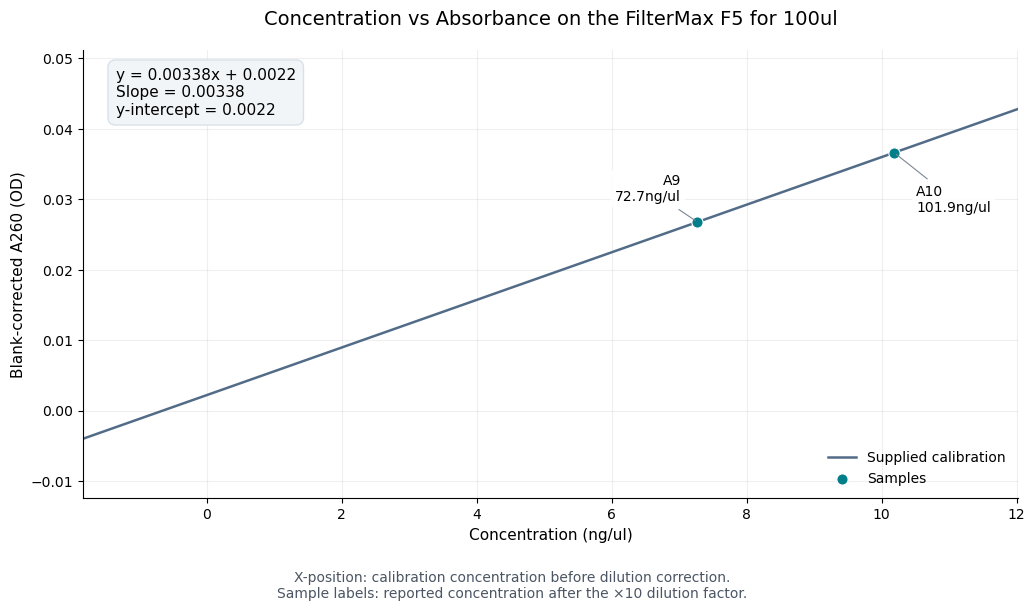

Graph: /home/hamilton-robot/Documents/hamilton-startlet-scripts/helper-scripts/runs/dna-a260-selected-20261008T142859Z-796dba1c/concentration_vs_absorbance.png


In [17]:
if analysis_table is None:
  print("Run the concentration-table cell with at least two finite readings first.")
else:
  figure = a260.plot_concentrations(analysis_table)
  plot_path = analysis_dir / "concentration_vs_absorbance.png"
  try:
    figure.savefig(plot_path, dpi=180, bbox_inches="tight")
    display(figure)
  finally:
    plt.close(figure)
  print("Graph:", plot_path)